In [4]:
import h5py
import numpy as np
import os
import matplotlib.pyplot as plt
from scipy.ndimage import label
from skimage import morphology
from skimage import measure
from scipy import ndimage as ndi
from skimage.segmentation import find_boundaries
from scipy.stats import gaussian_kde
from matplotlib.patches import FancyArrowPatch
from scipy.optimize import curve_fit
from scipy.ndimage import map_coordinates
import seaborn as sns
from scipy.ndimage import maximum_filter, label
from scipy.stats import skewnorm
from scipy.stats import lognorm
import fifpy
from scipy.ndimage import gaussian_filter
from scipy.ndimage import label, gaussian_filter
from scipy.stats import lognorm, gaussian_kde

# shared code and paths (see README.md and shared/)
import sys
from pathlib import Path
REPO = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "shared" / "paths.py").exists())
sys.path.insert(0, str(REPO))
from shared.detection import detect_current_sheets
from shared.fields import partial_x_fft, partial_y_fft
from shared.filtering import iterative_filtering1D, iterative_filtering3D
from shared.thickness import gaussian
from shared.paths import DATA_ROOT, NAS_ROOT, results_dir, cache_dir as shared_cache_dir
RESULTS = results_dir("cs_identification")
CACHE = shared_cache_dir("cs_identification")

In [5]:
#Defining all the required functions

#Fourier Transform Functions


#Defining constants
dx = 0.0625
dy = 0.0625






--- Processing beta = 0.0625, t = 40 ---
Loading cached filtered fields...


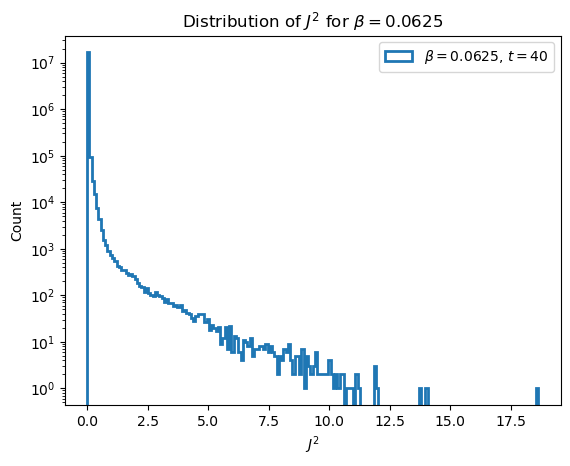

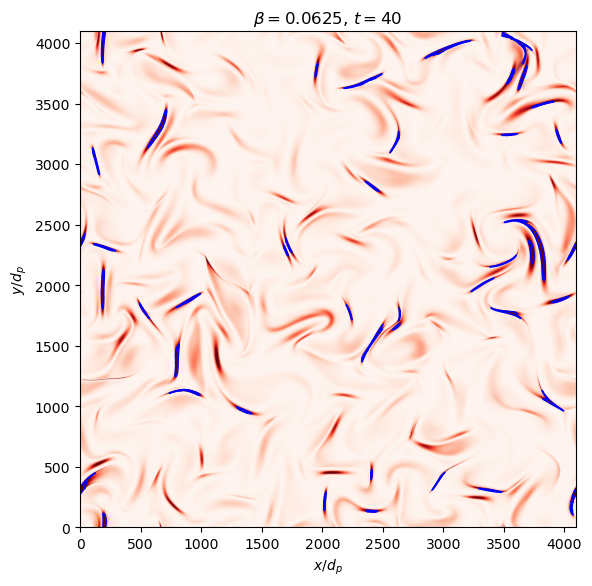

In [6]:
# -----------------------------
# USER SETTINGS
# -----------------------------
beta = 0.0625                  # pick one: 0.0625, 1, or 16
times = [40]             # add more snapshots here, e.g. [100, 150, 200]
cache_dir = str(CACHE / "filtered_cache")
os.makedirs(cache_dir, exist_ok=True)

# storage (keyed by time)
J2_all = {}
mask_all = {}

# ----- FILTER PARAMETERS (depend on beta) -----
if beta == 0.0625:
    n_iter, Xi = 1, 1.6
elif beta == 1:
    n_iter, Xi = 2, 2.0
else:
    n_iter, Xi = 3, 2.0

base_path = f'{DATA_ROOT}/beta_p_{beta}/beta_e_1/'

# -----------------------------
# MAIN LOOP (over times only)
# -----------------------------
for time in times:
    print(f"\n--- Processing beta = {beta}, t = {time} ---")

    File_Bx = base_path + f'Bx_ApJ_t{time}.h5'
    File_By = base_path + f'By_ApJ_t{time}.h5'
    File_Bz = base_path + f'Bz_ApJ_t{time}.h5'

    with h5py.File(File_Bx, 'r') as fBx, \
         h5py.File(File_By, 'r') as fBy, \
         h5py.File(File_Bz, 'r') as fBz:
        data_Bx = fBx['DS1'][:].T
        data_By = fBy['DS1'][:].T
        data_Bz = fBz['DS1'][:].T

    cache_file = f"{cache_dir}/filtered_beta_{beta}_t{time}_iter{n_iter}_Xi{Xi}.npz"

    if os.path.exists(cache_file):
        print("Loading cached filtered fields...")
        data = np.load(cache_file)
        data_Bx_f = data['Bx']
        data_By_f = data['By']
        data_Bz_f = data['Bz']
    else:
        print("Computing filtering (slow)...")
        data_Bx_f, data_By_f, data_Bz_f = iterative_filtering3D(
            data_Bx, data_By, data_Bz, n_iter, Xi=Xi
        )
        np.savez_compressed(
            cache_file, Bx=data_Bx_f, By=data_By_f, Bz=data_Bz_f
        )

    # ----- CURRENT DENSITY -----
    Jx = partial_y_fft(data_Bz_f, dx)
    Jy = -partial_x_fft(data_Bz_f, dy)
    Jz = partial_x_fft(data_By_f, dy) - partial_y_fft(data_Bx_f, dx)
    J2 = Jx**2 + Jy**2 + Jz**2

    plt.hist(J2.ravel(), bins=200, log=True,
             histtype='step', linewidth=2,
             label=fr'$\beta = {beta}$, $t = {time}$')

    # ----- CURRENT SHEET DETECTION -----
    sheets = detect_current_sheets(J2)
    mask = np.zeros_like(J2)
    for sheet in sheets:
        for (i, j) in sheet:
            mask[i, j] = 1

    # ----- MORPHOLOGICAL CLEANING -----
    struct = morphology.disk(1)
    mask = morphology.binary_opening(mask, struct)
    mask = morphology.binary_closing(mask, struct)
    mask = morphology.remove_small_objects(
        mask.astype(bool), min_size=500
    ).astype(int)

    J2_all[time] = J2
    mask_all[time] = mask

plt.legend()
plt.xlabel(r'$J^2$')
plt.ylabel('Count')
plt.title(fr'Distribution of $J^2$ for $\beta = {beta}$')
plt.show()

# -----------------------------
# COLOR SCALE
# -----------------------------
all_values = np.concatenate([v.ravel() for v in J2_all.values()])
vmax_global = np.percentile(all_values, 99)

# -----------------------------
# PLOT (one row of panels, one per time)
# -----------------------------
fig, axes = plt.subplots(
    1, len(times),
    figsize=(6 * len(times), 6),
    squeeze=False
)

for c, time in enumerate(times):
    ax = axes[0][c]
    im = ax.imshow(
        J2_all[time].T, cmap='Reds', origin='lower', vmax=vmax_global
    )
    ax.contour(
        mask_all[time].T, levels=[0.5], colors='blue', linewidths=1
    )
    ax.set_title(fr'$\beta = {beta}$, $t = {time}$')
    ax.set_xlabel(r'$x/d_p$')
    ax.set_ylabel(r'$y/d_p$')

plt.tight_layout()
plt.savefig(RESULTS / f"J2_comparison_beta_{beta}.png", dpi=300)
plt.show()

[t=40] Regions found: 44
[t=40] (M1) regions: 44
[t=40] M1 mean=17.713, median=15.678, min=7.211, max=40.000
[t=40] M2 mean=17.500, median=11.000, min=4.000, max=158.000
[t=40] M3 mean=13.359, median=11.290, min=2.719, max=81.462


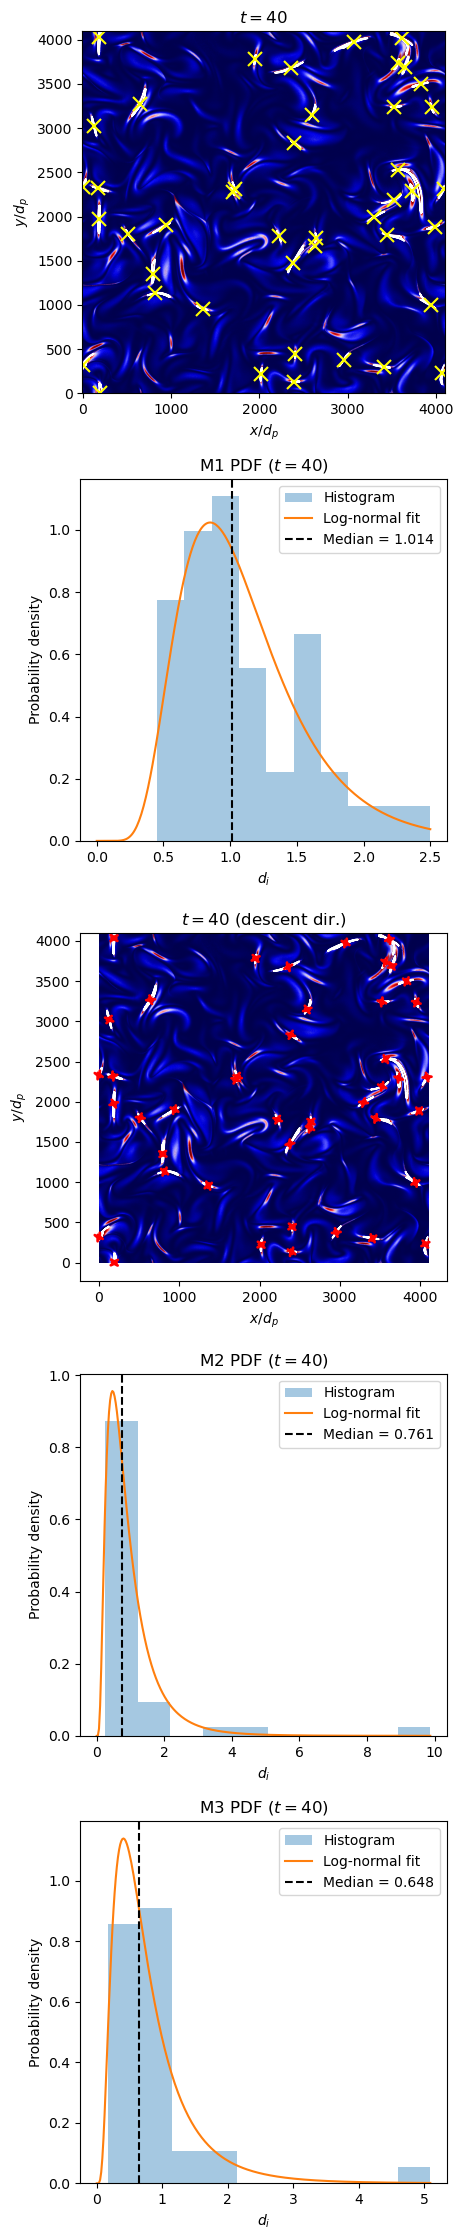

In [7]:
# ---------- Gaussian model for M3 ----------

# ---------- M3 sampling parameters ----------
max_len = 60
step_px = 1

# ---------- Pick which snapshot to analyse ----------
time = 40   # must match a key you stored in J2_all / mask_all

parent_save_folder = str(RESULTS / "gaussian_fits_J2_NR_aligning_methods")
os.makedirs(parent_save_folder, exist_ok=True)

# ---------- Figure: 5 rows x 1 col ----------
fig, axes = plt.subplots(5, 1, figsize=(4.5, 22.5))

ax_img_m1  = axes[0]
ax_hist_m1 = axes[1]
ax_img_m2  = axes[2]
ax_hist_m2 = axes[3]
ax_hist_m3 = axes[4]

cleaned_mask = mask_all[time]
J2 = J2_all[time]

# -----------------------------
# CONNECTED REGIONS (for maxima)
# -----------------------------
labeled_mask, num_features = label(cleaned_mask)
print(f"[t={time}] Regions found:", num_features)

max_coords = []
max_values = []

for i in range(1, num_features + 1):
    region_mask = (labeled_mask == i)
    region_vals = J2[region_mask]
    if region_vals.size == 0:
        continue
    max_pos = np.argmax(np.abs(region_vals))
    max_values.append(region_vals[max_pos])
    xs_r, ys_r = np.where(region_mask)
    max_coords.append((xs_r[max_pos], ys_r[max_pos]))

boundaries = find_boundaries(labeled_mask)

# -----------------------------
# ROW 0: FIELD + MAXIMA
# -----------------------------
ax_img_m1.imshow(J2.T, cmap='seismic', origin='lower', vmax=vmax_global)
ax_img_m1.contour(boundaries.T, levels=[0.5], colors='white', linewidths=1)
for x, y in max_coords:
    ax_img_m1.plot(x, y, marker='x', markersize=10,
                   markeredgewidth=1.5, color='yellow')
ax_img_m1.set_title(rf'$t = {time}$')
ax_img_m1.set_xlabel(r'$x/d_p$')
ax_img_m1.set_ylabel(r'$y/d_p$')

# -----------------------------
# METHOD 1 THICKNESS (distance transform)
# -----------------------------
labeled_mask_m1 = measure.label(cleaned_mask, connectivity=2)
num_regions = labeled_mask_m1.max()
print(f"[t={time}] (M1) regions:", num_regions)

thicknesses_m1 = []
for label_id in range(1, num_regions + 1):
    region = (labeled_mask_m1 == label_id)
    dist = ndi.distance_transform_edt(region)
    thicknesses_m1.append(2 * dist.max())

print(f"[t={time}] M1 mean={np.mean(thicknesses_m1):.3f}, "
      f"median={np.median(thicknesses_m1):.3f}, "
      f"min={np.min(thicknesses_m1):.3f}, max={np.max(thicknesses_m1):.3f}")

# -----------------------------
# ROW 1: M1 PDF + LOGNORMAL FIT
# -----------------------------
x_m1 = np.array(thicknesses_m1)
x_m1 = x_m1[x_m1 > 0]
x_m1_di = x_m1 / 16.0

shape_m1, loc_m1, scale_m1 = lognorm.fit(x_m1_di, floc=0)
xs_fit_m1 = np.linspace(0, x_m1_di.max(), 300)

ax_hist_m1.hist(x_m1_di, bins=10, density=True, alpha=0.4, label="Histogram")
ax_hist_m1.plot(xs_fit_m1, lognorm.pdf(xs_fit_m1, shape_m1, loc_m1, scale_m1),
                label="Log-normal fit")
ax_hist_m1.axvline(scale_m1, color='k', linestyle='--', linewidth=1.5,
                   label=f"Median = {scale_m1:.3f}")
ax_hist_m1.set_xlabel(r"$d_i$")
ax_hist_m1.set_ylabel("Probability density")
ax_hist_m1.set_title(rf'M1 PDF ($t = {time}$)')
ax_hist_m1.legend()

# -----------------------------
# METHOD 2: STEEPEST-DESCENT DIRECTIONS
# -----------------------------
sigma = 5
J2_smooth = gaussian_filter(J2, sigma=sigma)
dJdx, dJdy = np.gradient(J2_smooth)

descent_dirs = []
for (x, y) in max_coords:
    grad = np.array([dJdx[x, y], dJdy[x, y]])
    if np.allclose(grad, 0):
        descent_dirs.append(np.array([0.0, 0.0]))
    else:
        descent_dirs.append(-grad / np.linalg.norm(grad))

# -----------------------------
# ROW 2: FIELD + DESCENT ARROWS
# -----------------------------
ax_img_m2.imshow(J2.T, cmap='seismic', origin='lower',
                 vmax=vmax_global, aspect='equal', zorder=0)
ax_img_m2.contour(boundaries.T, levels=[0.5], colors='white',
                  linewidths=1, zorder=2)

factor = 200.0
for (x, y), (dx, dy) in zip(max_coords, descent_dirs):
    start = (x - 0.5 * factor * dx, y - 0.5 * factor * dy)
    end   = (x + 0.5 * factor * dx, y + 0.5 * factor * dy)
    arrow = FancyArrowPatch(start, end, arrowstyle="<->",
                            color="red", mutation_scale=10,
                            linewidth=2, zorder=10)
    ax_img_m2.add_patch(arrow)

ax_img_m2.set_title(rf'$t = {time}$ (descent dir.)')
ax_img_m2.set_xlabel(r'$x/d_p$')
ax_img_m2.set_ylabel(r'$y/d_p$')

# -----------------------------
# METHOD 2 THICKNESS (walk along descent dir.)
# -----------------------------
distances = []
step_size = 1
max_steps = 1000

for (x0, y0), (dx, dy) in zip(max_coords, descent_dirs):
    x0f, y0f = float(x0), float(y0)

    xf, yf = x0f, y0f
    steps = 0
    while steps < max_steps:
        xf_new = xf + dx * step_size
        yf_new = yf + dy * step_size
        xi, yi = int(round(xf_new)), int(round(yf_new))
        if (xi < 0 or yi < 0 or
            xi >= cleaned_mask.shape[0] or yi >= cleaned_mask.shape[1]):
            break
        if not cleaned_mask[xi, yi]:
            break
        xf, yf = xf_new, yf_new
        steps += 1
    dist_forward = np.hypot(xf - x0f, yf - y0f)

    xb, yb = x0f, y0f
    steps = 0
    while steps < max_steps:
        xb_new = xb - dx * step_size
        yb_new = yb - dy * step_size
        xi, yi = int(round(xb_new)), int(round(yb_new))
        if (xi < 0 or yi < 0 or
            xi >= cleaned_mask.shape[0] or yi >= cleaned_mask.shape[1]):
            break
        if not cleaned_mask[xi, yi]:
            break
        xb, yb = xb_new, yb_new
        steps += 1
    dist_backward = np.hypot(xb - x0f, yb - y0f)

    distances.append((dist_backward, dist_forward))

thicknesses_m2 = np.array([d[0] + d[1] for d in distances])
thicknesses_m2 = thicknesses_m2[thicknesses_m2 > 0]

print(f"[t={time}] M2 mean={np.mean(thicknesses_m2):.3f}, "
      f"median={np.median(thicknesses_m2):.3f}, "
      f"min={np.min(thicknesses_m2):.3f}, max={np.max(thicknesses_m2):.3f}")

# -----------------------------
# ROW 3: M2 PDF + LOGNORMAL FIT
# -----------------------------
x_m2_di = thicknesses_m2 / 16.0
x_m2_di = x_m2_di[x_m2_di > 0]

shape_m2, loc_m2, scale_m2 = lognorm.fit(x_m2_di, floc=0)
xs_fit_m2 = np.linspace(0, x_m2_di.max(), 300)

ax_hist_m2.hist(x_m2_di, bins=10, density=True, alpha=0.4, label="Histogram")
ax_hist_m2.plot(xs_fit_m2, lognorm.pdf(xs_fit_m2, shape_m2, loc_m2, scale_m2),
                label="Log-normal fit")
ax_hist_m2.axvline(scale_m2, color='k', linestyle='--', linewidth=1.5,
                   label=f"Median = {scale_m2:.3f}")
ax_hist_m2.set_xlabel(r"$d_i$")
ax_hist_m2.set_ylabel("Probability density")
ax_hist_m2.set_title(rf'M2 PDF ($t = {time}$)')
ax_hist_m2.legend()

# -----------------------------
# METHOD 3: FWHM via Gaussian fit along descent direction
# -----------------------------
fwhms = []
xs_list = []
vals_list = []
popts_list = []

for (x, y), (dx, dy) in zip(max_coords, descent_dirs):
    if dx == 0 and dy == 0:
        fwhms.append(np.nan)
        xs_list.append(np.array([]))
        vals_list.append(np.array([]))
        popts_list.append([np.nan]*4)
        continue

    xs, vals = [], []
    for k in range(-max_len, max_len + 1):
        xc = x + k * dx
        yc = y + k * dy
        xi, yi = int(round(xc)), int(round(yc))
        if 0 <= xi < J2.shape[0] and 0 <= yi < J2.shape[1]:
            xs.append(k)
            vals.append(J2[xi, yi])

    xs = np.array(xs)
    vals = np.array(vals)
    xs_list.append(xs)
    vals_list.append(vals)

    if len(vals) < 3:
        fwhms.append(np.nan)
        popts_list.append([np.nan]*4)
        continue

    A0 = vals.max() - vals.min()
    mu0 = xs[np.argmax(vals)]
    sigma0 = max_len / 4
    B0 = vals.min()

    try:
        popt, _ = curve_fit(gaussian, xs, vals, p0=[A0, mu0, sigma0, B0])
        A, mu, sigma_fit, B = popt
        fwhm = 2 * np.sqrt(2 * np.log(2)) * sigma_fit
        fwhms.append(fwhm)
        popts_list.append(popt)
    except RuntimeError:
        fwhms.append(np.nan)
        popts_list.append([np.nan]*4)

# Save individual Gaussian fits
beta_save_folder = os.path.join(parent_save_folder, f"t_{time}")
os.makedirs(beta_save_folder, exist_ok=True)

for i, (xs, vals, popt, fwhm) in enumerate(zip(xs_list, vals_list, popts_list, fwhms)):
    if len(xs) == 0 or np.isnan(popt[0]):
        continue
    A, mu, sigma_fit, B = popt
    x_dense = np.linspace(xs.min(), xs.max(), 500)
    fit_curve = A * np.exp(-(x_dense - mu)**2 / (2*sigma_fit**2)) + B

    fig_fit, ax_fit = plt.subplots()
    ax_fit.plot(xs, vals, 'o', label="sampled profile")
    ax_fit.plot(x_dense, fit_curve, label="Gaussian fit")
    ax_fit.set_title(f"t={time}, sample {i} — FWHM = {fwhm:.2f} px")
    ax_fit.set_xlabel("t (pixels)")
    ax_fit.set_ylabel("Intensity")
    ax_fit.legend()
    fig_fit.savefig(os.path.join(beta_save_folder, f"fit_{i:03d}.png"))
    plt.close(fig_fit)

# Filter FWHMs
fwhms_array = np.array(fwhms)
thicknesses_m3 = fwhms_array[~np.isnan(fwhms_array)]
thicknesses_m3 = thicknesses_m3[(thicknesses_m3 > 0) & (thicknesses_m3 <= 100)]

print(f"[t={time}] M3 mean={np.mean(thicknesses_m3):.3f}, "
      f"median={np.median(thicknesses_m3):.3f}, "
      f"min={np.min(thicknesses_m3):.3f}, max={np.max(thicknesses_m3):.3f}")

# -----------------------------
# ROW 4: M3 PDF + LOGNORMAL FIT
# -----------------------------
x_m3_di = thicknesses_m3 / 16.0

if x_m3_di.size > 0:
    shape_m3, loc_m3, scale_m3 = lognorm.fit(x_m3_di, floc=0)
    xs_fit_m3 = np.linspace(0, x_m3_di.max(), 300)
    ax_hist_m3.hist(x_m3_di, bins=10, density=True, alpha=0.4, label="Histogram")
    ax_hist_m3.plot(xs_fit_m3, lognorm.pdf(xs_fit_m3, shape_m3, loc_m3, scale_m3),
                    label="Log-normal fit")
    ax_hist_m3.axvline(scale_m3, color='k', linestyle='--', linewidth=1.5,
                       label=f"Median = {scale_m3:.3f}")
    ax_hist_m3.legend()

ax_hist_m3.set_xlabel(r"$d_i$")
ax_hist_m3.set_ylabel("Probability density")
ax_hist_m3.set_title(rf'M3 PDF ($t = {time}$)')

plt.tight_layout()
plt.savefig(RESULTS / f"J2_NR_M1_M2_M3_t{time}.png", dpi=300)
plt.show()

In [11]:
import os
import matplotlib.pyplot as plt
import numpy as np
from scipy.ndimage import label
from skimage.segmentation import find_boundaries

# ---------- pick snapshot ----------
time = 40
J2 = J2_all[time]
cleaned_mask = mask_all[time]

# ---------- output folder ----------
save_folder = str(RESULTS / f"current_sheets_t{time}")
os.makedirs(save_folder, exist_ok=True)

# ---------- label regions & find per-region maxima ----------
labeled_mask, num_features = label(cleaned_mask)
print(f"[t={time}] current sheets found:", num_features)

margin = 20  # pixels of padding around each sheet

for i in range(1, num_features + 1):
    region_mask = (labeled_mask == i)
    region_vals = J2[region_mask]
    if region_vals.size == 0:
        continue

    max_pos = np.argmax(np.abs(region_vals))
    xs_r, ys_r = np.where(region_mask)
    mx, my = xs_r[max_pos], ys_r[max_pos]

    x0 = max(xs_r.min() - margin, 0)
    x1 = min(xs_r.max() + margin, J2.shape[0] - 1)
    y0 = max(ys_r.min() - margin, 0)
    y1 = min(ys_r.max() + margin, J2.shape[1] - 1)

    boundary_i = find_boundaries(region_mask)

    J2_crop = J2[x0:x1+1, y0:y1+1]
    bnd_crop = boundary_i[x0:x1+1, y0:y1+1]

    fig, ax = plt.subplots(figsize=(6, 6))
    ax.imshow(J2_crop.T, cmap='seismic', origin='lower',
              vmax=vmax_global, extent=[x0, x1, y0, y1])
    ax.contour(bnd_crop.T, levels=[0.5], colors='white', linewidths=1.2,
               extent=[x0, x1, y0, y1])
    ax.plot(mx, my, marker='x', markersize=12,
            markeredgewidth=2, color='yellow')

    ax.set_title(rf'CS #{i}  ($t = {time}$)')
    ax.set_xlabel(r'$x/d_p$')
    ax.set_ylabel(r'$y/d_p$')
    plt.tight_layout()
    plt.savefig(os.path.join(save_folder, f"CS_{i:03d}_t{time}.png"), dpi=200)
    plt.close(fig)

print(f"Saved {num_features} current-sheet images to '{save_folder}/'")

[t=40] current sheets found: 44
Saved 44 current-sheet images to 'current_sheets_t40/'


In [8]:
import os
import numpy as np
import matplotlib.pyplot as plt
from scipy.ndimage import label, gaussian_filter
from skimage.segmentation import find_boundaries
from matplotlib.patches import FancyArrowPatch

# ---------- pick snapshot ----------
time = 40
J2 = J2_all[time]
cleaned_mask = mask_all[time]

# ---------- output folder ----------
save_folder = str(RESULTS / f"current_sheets_t{time}")
os.makedirs(save_folder, exist_ok=True)

# ---------- smoothed gradient (descent directions) ----------
sigma = 3
J2_smooth = gaussian_filter(J2, sigma=sigma)
dJdx, dJdy = np.gradient(J2_smooth)

# ---------- label regions ----------
labeled_mask, num_features = label(cleaned_mask)
print(f"[t={time}] current sheets found:", num_features)

margin = 20
arrow_factor = 60.0  # arrow length in pixels; tune to taste

for i in range(1, num_features + 1):
    region_mask = (labeled_mask == i)
    region_vals = J2[region_mask]
    if region_vals.size == 0:
        continue

    max_pos = np.argmax(np.abs(region_vals))
    xs_r, ys_r = np.where(region_mask)
    mx, my = xs_r[max_pos], ys_r[max_pos]

    # descent direction at the maximum (negative smoothed gradient)
    grad = np.array([dJdx[mx, my], dJdy[mx, my]])
    if np.allclose(grad, 0):
        ddir = np.array([0.0, 0.0])
    else:
        ddir = -grad / np.linalg.norm(grad)

    x0 = max(xs_r.min() - margin, 0)
    x1 = min(xs_r.max() + margin, J2.shape[0] - 1)
    y0 = max(ys_r.min() - margin, 0)
    y1 = min(ys_r.max() + margin, J2.shape[1] - 1)

    boundary_i = find_boundaries(region_mask)
    J2_crop = J2[x0:x1+1, y0:y1+1]
    bnd_crop = boundary_i[x0:x1+1, y0:y1+1]

    fig, ax = plt.subplots(figsize=(6, 6))
    ax.imshow(J2_crop.T, cmap='seismic', origin='lower',
              vmax=vmax_global, extent=[x0, x1, y0, y1], zorder=0)
    ax.contour(bnd_crop.T, levels=[0.5], colors='white', linewidths=1.2,
               extent=[x0, x1, y0, y1], zorder=2)
    ax.plot(mx, my, marker='x', markersize=12,
            markeredgewidth=2, color='yellow', zorder=5)

    # double-headed descent arrow through the maximum
    dx, dy = ddir
    if not (dx == 0 and dy == 0):
        start = (mx - 0.5 * arrow_factor * dx, my - 0.5 * arrow_factor * dy)
        end   = (mx + 0.5 * arrow_factor * dx, my + 0.5 * arrow_factor * dy)
        arrow = FancyArrowPatch(start, end, arrowstyle="<->",
                                color="red", mutation_scale=12,
                                linewidth=2, zorder=10)
        ax.add_patch(arrow)

    ax.set_xlim(x0, x1)
    ax.set_ylim(y0, y1)
    ax.set_title(rf'CS #{i}  ($t = {time}$)')
    ax.set_xlabel(r'$x/d_p$')
    ax.set_ylabel(r'$y/d_p$')
    plt.tight_layout()
    plt.savefig(os.path.join(save_folder, f"CS_{i:03d}_t{time}.png"), dpi=200)
    plt.close(fig)

print(f"Saved {num_features} current-sheet images to '{save_folder}/'")

[t=40] current sheets found: 44
Saved 44 current-sheet images to 'current_sheets_t40/'
